Saved


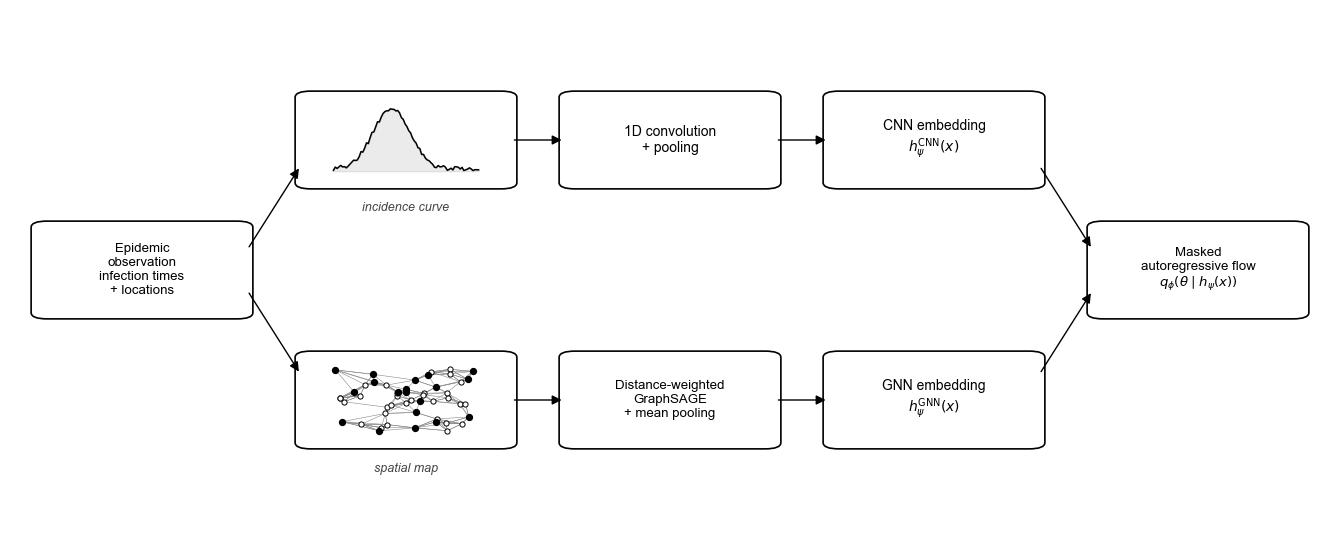

In [152]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy.spatial.distance import cdist
import numpy as np

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

fig, ax = plt.subplots(figsize=(13.5, 5.5))
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

def box(xc, yc, w, h, text=None, fontsize=10):
    p = FancyBboxPatch(
        (xc - w/2, yc - h/2), w, h,
        boxstyle="round,pad=0.4,rounding_size=1.2",
        linewidth=1.2, edgecolor="black", facecolor="white",
    )
    ax.add_patch(p)
    if text:
        ax.text(xc, yc, text, ha="center", va="center", fontsize=fontsize)

def arrow(x1, y1, x2, y2):
    a = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>", mutation_scale=14,
        linewidth=1.0, color="black",
    )
    ax.add_patch(a)
y_top, y_mid, y_bot = 75, 50, 25
W, H = 16, 18
x1, x2, x3, x4, x5 = 10, 30, 50, 70, 90

box(x1, y_mid, W, H,
    "Epidemic\nobservation\ninfection times\n+ locations", fontsize=9.5)
box(x2, y_top, W, H)
np.random.seed(7)
t = np.linspace(0, 1, 80)
inc = 4 * np.exp(-((t - 0.4) / 0.18) ** 2) + np.random.uniform(0, 0.3, 80)
xc = (x2 - W/2 + 2.5) + t * (W - 5)
yc = (y_top - H/2 + 3) + (inc / inc.max()) * (H - 6)
ax.plot(xc, yc, color="black", lw=1.1)
ax.fill_between(xc, y_top - H/2 + 3, yc, color="black", alpha=0.08)
ax.text(x2, y_top - H/2 - 3, "incidence curve",
        ha="center", va="top", fontsize=9, style="italic", color="#444")

box(x2, y_bot, W, H)
np.random.seed(1234)
n_farms = 50
px = np.random.uniform(x2 - W/2 + 2.5, x2 + W/2 - 2.5, n_farms)
py = np.random.uniform(y_bot - H/2 + 3, y_bot + H/2 - 3, n_farms)
D = cdist(np.column_stack([px, py]), np.column_stack([px, py]))
np.fill_diagonal(D, np.inf)
k_nn = 5
for i in range(n_farms):
    for j in np.argsort(D[i])[:k_nn]:
        ax.plot([px[i], px[j]], [py[i], py[j]],
                color="#888", lw=0.4, zorder=1)
infected = np.random.rand(n_farms) < 0.32
ax.scatter(px[~infected], py[~infected], s=14,
           color="white", edgecolors="black", linewidths=0.7, zorder=3)
ax.scatter(px[infected], py[infected], s=18,
           color="black", zorder=4)
ax.text(x2, y_bot - H/2 - 3, "spatial map",
        ha="center", va="top", fontsize=9, style="italic", color="#444")
box(x3, y_top, W, H, "1D convolution\n+ pooling")
box(x3, y_bot, W, H, "Distance-weighted\nGraphSAGE\n+ mean pooling", fontsize=9.5)
box(x4, y_top, W, H, "CNN embedding\n$h_\\psi^{\\mathrm{CNN}}(x)$")
box(x4, y_bot, W, H, "GNN embedding\n$h_\\psi^{\\mathrm{GNN}}(x)$")
box(x5, y_mid, W, H,
    "Masked\nautoregressive flow\n$q_\\phi(\\theta \\mid h_\\psi(x))$", fontsize=9.5)

arrow(x1 + W/2, y_mid + 4, x2 - W/2, y_top - 5)
arrow(x1 + W/2, y_mid - 4, x2 - W/2, y_bot + 5)

arrow(x2 + W/2, y_top, x3 - W/2, y_top)
arrow(x3 + W/2, y_top, x4 - W/2, y_top)
arrow(x4 + W/2, y_top - 5, x5 - W/2, y_mid + 4)

arrow(x2 + W/2, y_bot, x3 - W/2, y_bot)
arrow(x3 + W/2, y_bot, x4 - W/2, y_bot)
arrow(x4 + W/2, y_bot + 5, x5 - W/2, y_mid - 4)

plt.tight_layout()
plt.savefig("figures/Fig_npe_architecture.pdf", bbox_inches="tight", dpi=300)
plt.savefig("figures/Fig_npe_architecture.png", bbox_inches="tight", dpi=200)
print("Saved")

Saved


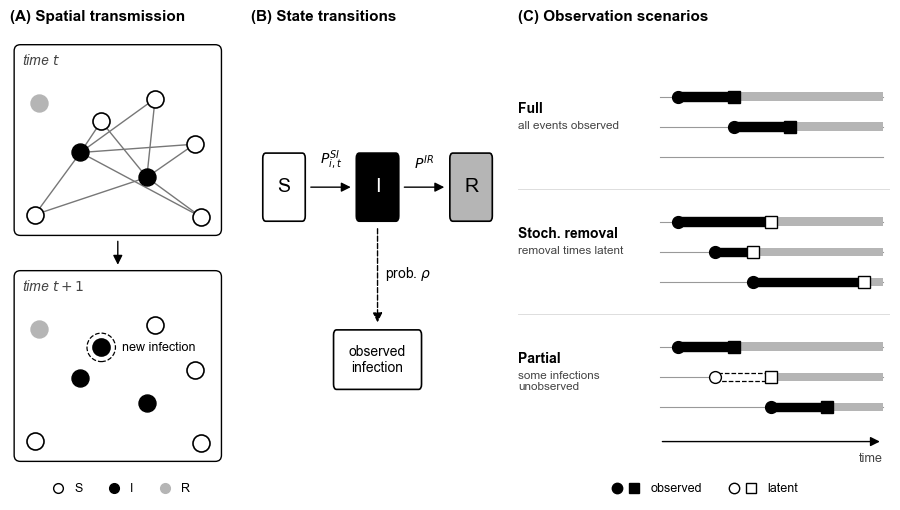

In [153]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

C_S = "white"
C_I = "black"
C_R = "#b5b5b5"
GREY_TXT = "#444"

def box(ax, xc, yc, w, h, text=None, fontsize=10, fc="white", tc="black"):
    ax.add_patch(FancyBboxPatch(
        (xc - w/2, yc - h/2), w, h,
        boxstyle="round,pad=0.4,rounding_size=1.2",
        linewidth=1.2, edgecolor="black", facecolor=fc))
    if text:
        ax.text(xc, yc, text, ha="center", va="center",
                fontsize=fontsize, color=tc, zorder=5)

def arrow(ax, x1, y1, x2, y2, label=None, dy=3.5, fontsize=10, ls="-"):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14,
        linewidth=1.0, color="black", linestyle=ls))
    if label:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + dy, label,
                ha="center", va="bottom", fontsize=fontsize)

PANEL_LABELS = []
def panel_label(ax, text):
    PANEL_LABELS.append((ax, text))

fig = plt.figure(figsize=(11.5, 5.6))
gs = fig.add_gridspec(1, 3, width_ratios=[0.8, 0.85, 1.25], wspace=0.05)
axA = fig.add_subplot(gs[0])
axB = fig.add_subplot(gs[1])
axC = fig.add_subplot(gs[2])

I_pos = [(32, 40), (64, 28)]
S_pos = [(42, 55), (87, 44), (10, 10), (90, 9), (68, 66)]
R_pos = [(12, 64)]
NEW = {0}

Y_TOP, Y_BOT, BOX_H = 112, 3, 92
def snapshot(y0, title, show_lines, new):
    axA.add_patch(FancyBboxPatch((0, y0), 100, BOX_H,
                  boxstyle="round,pad=0,rounding_size=3",
                  lw=1.0, ec="black", fc="white"))
    axA.text(4, y0 + BOX_H - 4, title, ha="left", va="top", fontsize=10,
             style="italic", color=GREY_TXT)
    off = lambda p: (p[0], p[1] + y0)
    if show_lines:
        for ps in S_pos:
            for pi in I_pos:
                (x1, y1), (x2, y2) = off(ps), off(pi)
                axA.plot([x1, x2], [y1, y2], color="#777", lw=1.0, zorder=1)
    for p in R_pos:
        axA.scatter(*off(p), s=150, c=C_R, zorder=3)
    for p in I_pos:
        axA.scatter(*off(p), s=150, c=C_I, zorder=3)
    for i, p in enumerate(S_pos):
        infected = i in new
        axA.scatter(*off(p), s=150, c=C_I if infected else C_S,
                    edgecolors="black", linewidths=1.2, zorder=3)
        if infected:
            axA.scatter(*off(p), s=420, facecolors="none", edgecolors="black",
                        linewidths=0.9, linestyle="--", zorder=2)
            axA.annotate("new infection", off(p), xytext=(15, 0),
                         textcoords="offset points", fontsize=9,
                         ha="left", va="center")

snapshot(Y_TOP, "time $t$", True, set())
snapshot(Y_BOT, "time $t+1$", False, NEW)
axA.add_patch(FancyArrowPatch((50, Y_TOP - 1.5), (50, Y_BOT + BOX_H + 1.5),
              arrowstyle="-|>", mutation_scale=14, lw=1.0, color="black"))

axA.set_xlim(-2, 102)
axA.set_ylim(-2, Y_TOP + BOX_H + 2)
axA.set_aspect("equal")
axA.axis("off")
panel_label(axA, "(A) Spatial transmission")

handles = [
    Line2D([], [], marker="o", ls="", mfc=C_S, mec="black", mew=1.0, ms=7, label="S"),
    Line2D([], [], marker="o", ls="", mfc=C_I, mec=C_I, ms=7, label="I"),
    Line2D([], [], marker="o", ls="", mfc=C_R, mec=C_R, ms=7, label="R"),
]
axA.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=3, fontsize=9, frameon=False, handletextpad=0.3,
           columnspacing=1.5)

axB.set_xlim(0, 100); axB.set_ylim(0, 100); axB.axis("off")
panel_label(axB, "(B) State transitions")

xs, xi, xr = 13, 50, 87
bw, bh = 16, 15
yr = 66
box(axB, xs, yr, bw, bh, "S", fontsize=14)
box(axB, xi, yr, bw, bh, "I", fontsize=14, fc=C_I, tc="white")
box(axB, xr, yr, bw, bh, "R", fontsize=14, fc=C_R)
arrow(axB, xs + bw/2 + 1.5, yr, xi - bw/2 - 1.5, yr, r"$P^{SI}_{i,t}$")
arrow(axB, xi + bw/2 + 1.5, yr, xr - bw/2 - 1.5, yr, r"$P^{IR}$")

yo = 26
box(axB, xi, yo, 34, 13, "observed\ninfection", fontsize=10)
arrow(axB, xi, yr - bh/2 - 1.5, xi, yo + 13/2 + 1.5, ls="--")
axB.text(xi + 3, (yr + yo) / 2, r"prob. $\rho$", ha="left", va="center",
         fontsize=10)

axC.set_xlim(0, 100); axC.set_ylim(0, 100); axC.axis("off")
panel_label(axC, "(C) Observation scenarios")

T_MAX = 12
X0, X1 = 38, 98
def tx(t):
    return X0 + t / T_MAX * (X1 - X0)

BAR_H = 2.0
def draw_ind(y, bars, marks):
    axC.plot([tx(0), tx(T_MAX)], [y, y], color="#999", lw=0.8, zorder=1)
    for kind, t0, t1 in bars:
        kw = {"I": dict(fc=C_I, ec=C_I),
              "R": dict(fc=C_R, ec="none"),
              "Ihid": dict(fc="white", ec="black", ls="--", lw=0.9)}[kind]
        axC.add_patch(Rectangle((tx(t0), y - BAR_H/2), tx(t1) - tx(t0),
                                BAR_H, zorder=2, **kw))
    for t, shape, observed in marks:
        axC.plot(tx(t), y, marker=shape, ms=8.5, ls="",
                 mfc="black" if observed else "white", mec="black",
                 mew=1.0, zorder=4)

rows = [
    ("Full", "all events observed",
     [dict(bars=[("I", 1, 4), ("R", 4, T_MAX)], marks=[(1, "o", 1), (4, "s", 1)]),
      dict(bars=[("I", 4, 7), ("R", 7, T_MAX)], marks=[(4, "o", 1), (7, "s", 1)]),
      dict(bars=[], marks=[])]),
    ("Stoch. removal", "removal times latent",
     [dict(bars=[("I", 1, 6), ("R", 6, T_MAX)], marks=[(1, "o", 1), (6, "s", 0)]),
      dict(bars=[("I", 3, 5), ("R", 5, T_MAX)], marks=[(3, "o", 1), (5, "s", 0)]),
      dict(bars=[("I", 5, 11), ("R", 11, T_MAX)], marks=[(5, "o", 1), (11, "s", 0)])]),
    ("Partial", "some infections\nunobserved",
     [dict(bars=[("I", 1, 4), ("R", 4, T_MAX)], marks=[(1, "o", 1), (4, "s", 1)]),
      dict(bars=[("Ihid", 3, 6), ("R", 6, T_MAX)], marks=[(3, "o", 0), (6, "s", 0)]),
      dict(bars=[("I", 6, 9), ("R", 9, T_MAX)], marks=[(6, "o", 1), (9, "s", 1)])]),
]

centres = [80, 51, 22]
for k, ((name, note, inds), yc) in enumerate(zip(rows, centres)):
    axC.text(0, yc + 2.5, name, fontsize=10, fontweight="bold", va="bottom")
    axC.text(0, yc + 1.5, note, fontsize=8.5, color=GREY_TXT, va="top",
             linespacing=1.2)
    for ind, dy in zip(inds, [7, 0, -7]):
        draw_ind(yc + dy, ind["bars"], ind["marks"])
    if k < len(rows) - 1:
        axC.plot([0, 100], [yc - 14.5, yc - 14.5], color="#d8d8d8", lw=0.6)

arrow(axC, tx(0), 7, tx(T_MAX), 7)
axC.text(tx(T_MAX), 4.5, "time", ha="right", va="top", fontsize=9,
         color=GREY_TXT)

mk = dict(ms=7.5, ls="", mec="black", mew=1.0)
obs_h = (Line2D([], [], marker="o", mfc="black", **mk),
         Line2D([], [], marker="s", mfc="black", **mk))
lat_h = (Line2D([], [], marker="o", mfc="white", **mk),
         Line2D([], [], marker="s", mfc="white", **mk))
axC.legend([obs_h, lat_h], ["observed", "latent"],
           handler_map={tuple: HandlerTuple(ndivide=None, pad=0.3)},
           loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2,
           fontsize=9, frameon=False, handlelength=2.4, columnspacing=2.0)

fig.canvas.draw()
top = max(a.get_position().y1 for a, _ in PANEL_LABELS) + 0.03
for a, text in PANEL_LABELS:
    fig.text(a.get_position().x0, top, text, ha="left", va="bottom",
             fontsize=11, fontweight="bold")

plt.savefig("figures/Fig_model.pdf", bbox_inches="tight", dpi=300)
plt.savefig("figures/Fig_model.png", bbox_inches="tight", dpi=200)
print("Saved")

In [154]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm
from scipy.stats import gaussian_kde, spearmanr

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

ROOT = Path("/Users/MYC/Desktop/博后项目/NPE_embed_ILM/9.25")
OUT = ROOT / "output"
FIG_DIR = ROOT / "figures"
EVAL_ROOT = OUT / "strict_seeds" / "seed_1"

SCENARIOS = ["full", "gamma", "partial"]
SCENARIO_LABELS = {"full": "Full", "gamma": "Stoch. removal", "partial": "Partial"}
SCENARIO_PARAMS = {"full": ["alpha", "beta"], "gamma": ["alpha", "beta", "gamma"], "partial": ["alpha", "beta", "rho"]}
PARAM_TEX = {"alpha": r"$\alpha$", "beta": r"$\beta$", "gamma": r"$\gamma$", "rho": r"$\rho$", "R0": r"$R_0$"}
METHOD_ORDER = ["CNN-NPE", "GNN-NPE", "MCMC"]
METHOD_KEYS = {"CNN-NPE": "cnn", "GNN-NPE": "gnn", "MCMC": "mcmc"}
METHOD_COLORS = {"CNN-NPE": "#0072B2", "GNN-NPE": "#D55E00", "MCMC": "#009E73"}
METHOD_MARKERS = {"CNN-NPE": "o", "GNN-NPE": "s", "MCMC": "^"}
BAND_COLOR = "#BBBBBB"
PRIOR_VARIANTS = ["baseline", "all_tighter", "bR0_tighter", "d_tighter", "d_wider", "bR0_wider", "all_wider"]
PRIOR_LABELS = {v: f"Prior {k + 1}" for k, v in enumerate(PRIOR_VARIANTS)}
PRIOR_COLORS = dict(zip(PRIOR_VARIANTS, ["#000000", "#E69F00", "#56B4E9", "#009E73", "#CC79A7", "#0072B2", "#D55E00"]))


def style(ax):
    ax.tick_params(axis="both", labelsize=8.5, length=3)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)


def panel_label(ax, letter):
    ax.text(-0.12, 1.05, f"({letter})", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")


def top_legend(fig, handles, y=1.0, x=0.5, ncol=None, fontsize=10):
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(x, y), ncol=ncol or len(handles), frameon=False,
               fontsize=fontsize, columnspacing=1.6)


def scenario_grid(n_rows=3, height=2.9):
    fig, axes = plt.subplots(n_rows, 3, figsize=(10.5, height * n_rows + 0.5), squeeze=False)
    return fig, axes


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

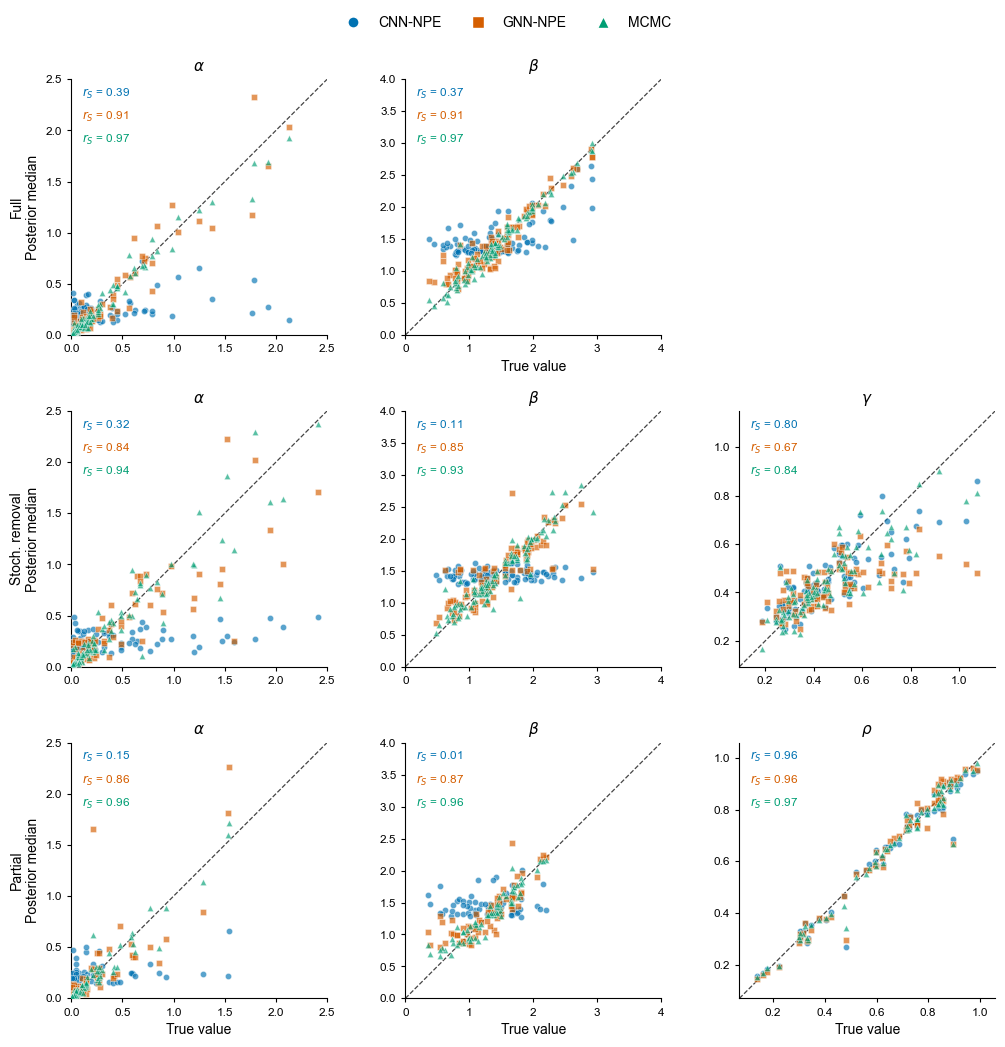

In [155]:
LIMITS = {"alpha": (0.0, 2.5), "beta": (0.0, 4.0)}
FILES = {"CNN-NPE": "param_level_cnn_mcmc_subset.csv", "GNN-NPE": "param_level_gnn_mcmc_subset.csv",
         "MCMC": "param_level_mcmc.csv"}

fig, axes = scenario_grid(height=3.2)
for r, sc in enumerate(SCENARIOS):
    lv = {m: pd.read_csv(EVAL_ROOT / sc / "eval" / f) for m, f in FILES.items()}
    params = SCENARIO_PARAMS[sc]
    for c in range(3):
        ax = axes[r, c]
        if c >= len(params):
            ax.set_visible(False)
            continue
        p = params[c]
        subs = {m: d[d["parameter"] == p] for m, d in lv.items()}
        if p in LIMITS:
            lo, hi = LIMITS[p]
        else:
            v = np.concatenate([np.r_[s["true"], s["post_median"]] for s in subs.values()])
            pad = 0.08 * (v.max() - v.min())
            lo, hi = v.min() - pad, v.max() + pad
        ax.plot([lo, hi], [lo, hi], color="#444444", linewidth=0.9, linestyle="--", zorder=1)
        for k, m in enumerate(METHOD_ORDER):
            s = subs[m]
            ax.scatter(s["true"], s["post_median"], s=20, marker=METHOD_MARKERS[m], facecolor=METHOD_COLORS[m],
                       edgecolor="white", linewidth=0.4, alpha=0.65, rasterized=True, zorder=3)
            ax.text(0.04, 0.97 - 0.09 * k, f"$r_S$ = {spearmanr(s['true'], s['post_median'])[0]:.2f}",
                    transform=ax.transAxes, ha="left", va="top", fontsize=8.5, color=METHOD_COLORS[m])
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(PARAM_TEX[p], fontsize=11)
        style(ax)
        if c == 0:
            ax.set_ylabel(f"{SCENARIO_LABELS[sc]}\nPosterior median", fontsize=10)
        if r == len(SCENARIOS) - 1 or (r == 0 and c == len(params) - 1):
            ax.set_xlabel("True value", fontsize=10)
handles = [Line2D([0], [0], marker=METHOD_MARKERS[m], color="none", markerfacecolor=METHOD_COLORS[m],
                  markeredgecolor="white", markersize=8, label=m) for m in METHOD_ORDER]
fig.tight_layout()
top_legend(fig, handles)
save(fig, "Fig_recovery_npe_mcmc")

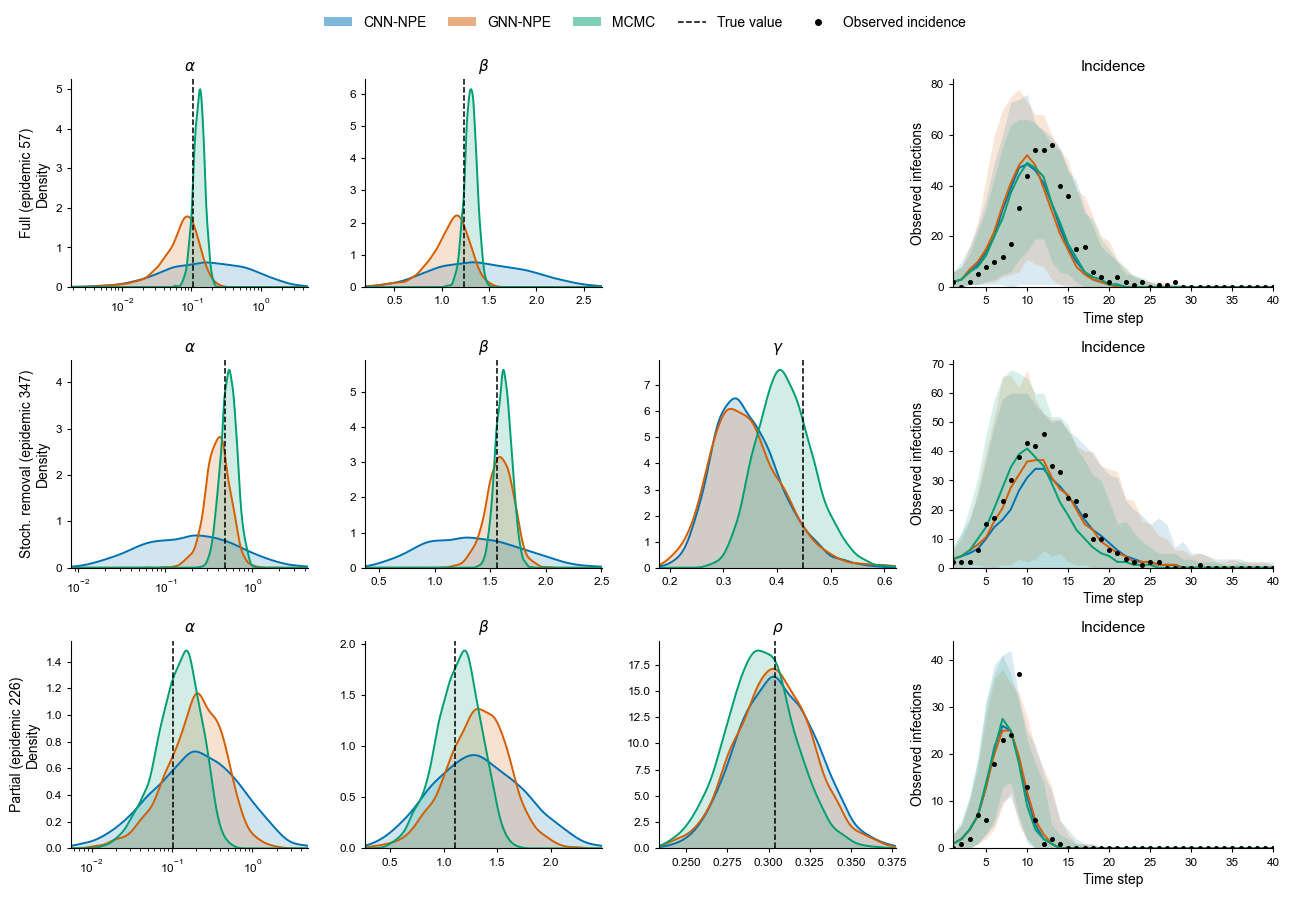

In [156]:
PPC_ROOT = OUT / "individual_ppc"


def density_panel(ax, d, j, p):
    vals = {m: d[f"{METHOD_KEYS[m]}_samples"][:, j].astype(float) for m in METHOD_ORDER}
    truth = float(d["theta"][j])
    if p == "alpha":
        vals = {m: np.log10(v) for m, v in vals.items()}
        truth = np.log10(truth)
    pooled = np.concatenate(list(vals.values()))
    lo, hi = np.quantile(pooled, [0.002, 0.998])
    lo, hi = min(lo, truth), max(hi, truth)
    pad = 0.05 * (hi - lo)
    grid = np.linspace(lo - pad, hi + pad, 400)
    x = 10 ** grid if p == "alpha" else grid
    for m in METHOD_ORDER:
        dens = gaussian_kde(vals[m])(grid)
        ax.fill_between(x, dens, color=METHOD_COLORS[m], alpha=0.18, linewidth=0)
        ax.plot(x, dens, color=METHOD_COLORS[m], linewidth=1.4)
    ax.axvline(10 ** truth if p == "alpha" else truth, color="black", linestyle="--", linewidth=1.1)
    if p == "alpha":
        ax.set_xscale("log")
    ax.set_xlim(x[0], x[-1])
    ax.set_ylim(bottom=0)


def ppc_panel(ax, d):
    T = len(d["observed_curve"])
    days = np.arange(1, T + 1)
    for m in METHOD_ORDER:
        lo, med, hi = np.percentile(d[f"{METHOD_KEYS[m]}_curves"], [2.5, 50, 97.5], axis=0)
        ax.fill_between(days, lo, hi, color=METHOD_COLORS[m], alpha=0.15, linewidth=0)
        ax.plot(days, med, color=METHOD_COLORS[m], linewidth=1.4)
    ax.plot(days, d["observed_curve"], color="black", linestyle="none", marker="o", markersize=2.6)
    ax.set_xlim(1, T)
    ax.set_ylim(bottom=0)


fig, axes = plt.subplots(3, 4, figsize=(13.0, 8.6), squeeze=False, gridspec_kw={"width_ratios": [1, 1, 1, 1.35]})
for r, sc in enumerate(SCENARIOS):
    z = np.load(PPC_ROOT / sc / "selected_q50.npz", allow_pickle=True)
    d = {k: z[k] for k in z.files}
    params = [str(p) for p in d["param_names"]]
    for c in range(3):
        ax = axes[r, c]
        if c >= len(params):
            ax.set_visible(False)
            continue
        density_panel(ax, d, c, params[c])
        ax.set_title(PARAM_TEX[params[c]], fontsize=11)
        style(ax)
    ppc_panel(axes[r, 3], d)
    axes[r, 3].set_title("Incidence", fontsize=11)
    axes[r, 3].set_ylabel("Observed infections", fontsize=10)
    axes[r, 3].set_xlabel("Time step", fontsize=10)
    style(axes[r, 3])
    axes[r, 0].set_ylabel(f"{SCENARIO_LABELS[sc]} (epidemic {int(d['obs_idx'])})\nDensity", fontsize=10)
handles = [Patch(facecolor=METHOD_COLORS[m], alpha=0.5, label=m) for m in METHOD_ORDER]
handles += [Line2D([0], [0], color="black", linestyle="--", linewidth=1.1, label="True value"),
            Line2D([0], [0], color="black", linestyle="none", marker="o", markersize=4, label="Observed incidence")]
fig.tight_layout()
top_legend(fig, handles)
save(fig, "Fig_individual_npe_mcmc")

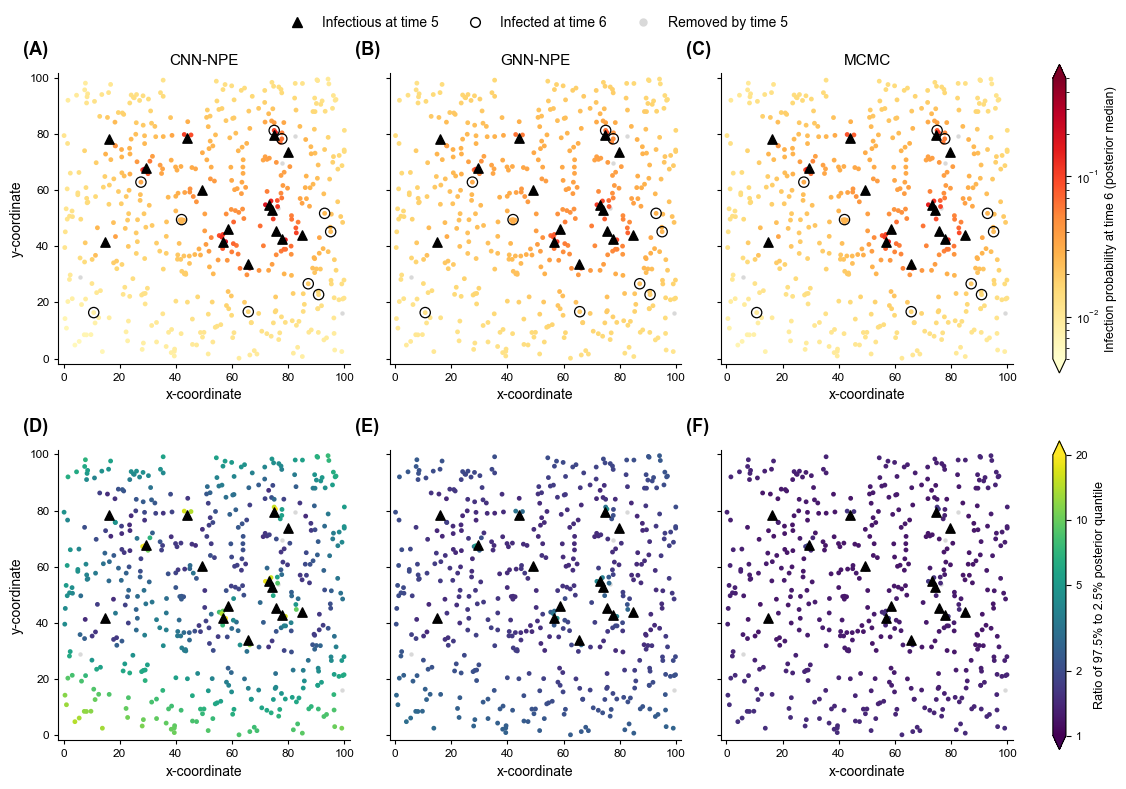

In [157]:
RISK_RANGE = (5e-3, 0.5)
RATIO_RANGE = (1.0, 20.0)
C_OTHER = "#d9d9d9"

rk = np.load(OUT / "spatial_risk" / "risk_map.npz")
pos = rk["positions"].astype(float)
sus, inf, nxt = rk["susceptible"], rk["infectious"], rk["exposed_next"]
before = np.setdiff1d(rk["infected_before"], inf)
t = int(rk["t"])
xlim = (pos[:, 0].min() - 2, pos[:, 0].max() + 2)
ylim = (pos[:, 1].min() - 2, pos[:, 1].max() + 2)

fig = plt.figure(figsize=(13.0, 8.9))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.045], wspace=0.18, hspace=0.22)
rows = [("median", LogNorm(*RISK_RANGE), "YlOrRd", f"Infection probability at time {t + 1} (posterior median)"),
        ("ratio", LogNorm(*RATIO_RANGE), "viridis", "Ratio of 97.5% to 2.5% posterior quantile")]
for r_, (kind, norm, cmap, cb_label) in enumerate(rows):
    for c, m in enumerate(METHOD_ORDER):
        ax = fig.add_subplot(gs[r_, c])
        k = METHOD_KEYS[m]
        val = rk[f"{k}_median"] if kind == "median" else rk[f"{k}_q975"] / rk[f"{k}_q025"]
        order = np.argsort(val)
        ax.scatter(pos[before, 0], pos[before, 1], s=10, color=C_OTHER, linewidths=0, zorder=1)
        sc_ = ax.scatter(pos[sus[order], 0], pos[sus[order], 1], c=val[order], cmap=cmap, norm=norm, s=12,
                         linewidths=0, zorder=2)
        if kind == "median":
            ax.scatter(pos[nxt, 0], pos[nxt, 1], s=55, facecolors="none", edgecolors="black", linewidths=0.9, zorder=3)
        ax.scatter(pos[inf, 0], pos[inf, 1], marker="^", s=45, color="black", zorder=4)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x-coordinate", fontsize=10)
        if c == 0:
            ax.set_ylabel("y-coordinate", fontsize=10)
        else:
            ax.set_yticklabels([])
        if r_ == 0:
            ax.set_title(m, fontsize=11)
        style(ax)
        panel_label(ax, "ABCDEF"[3 * r_ + c])
    cb = fig.colorbar(sc_, cax=fig.add_subplot(gs[r_, 3]), extend="both")
    cb.set_label(cb_label, fontsize=9)
    cb.ax.tick_params(labelsize=8)
    if kind == "ratio":
        cb.set_ticks([1, 2, 5, 10, 20])
        cb.set_ticklabels(["1", "2", "5", "10", "20"])
        cb.ax.minorticks_off()
handles = [
    Line2D([0], [0], marker="^", linestyle="none", color="black", markersize=7, label=f"Infectious at time {t}"),
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="none", markeredgecolor="black", markersize=7,
           label=f"Infected at time {t + 1}"),
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=C_OTHER, markeredgecolor=C_OTHER, markersize=5,
           label=f"Removed by time {t}"),
]
x0, x1 = fig.axes[0].get_position().x0, fig.axes[2].get_position().x1
top_legend(fig, handles, x=(x0 + x1) / 2, y=0.905)
save(fig, "Fig_sim_risk")

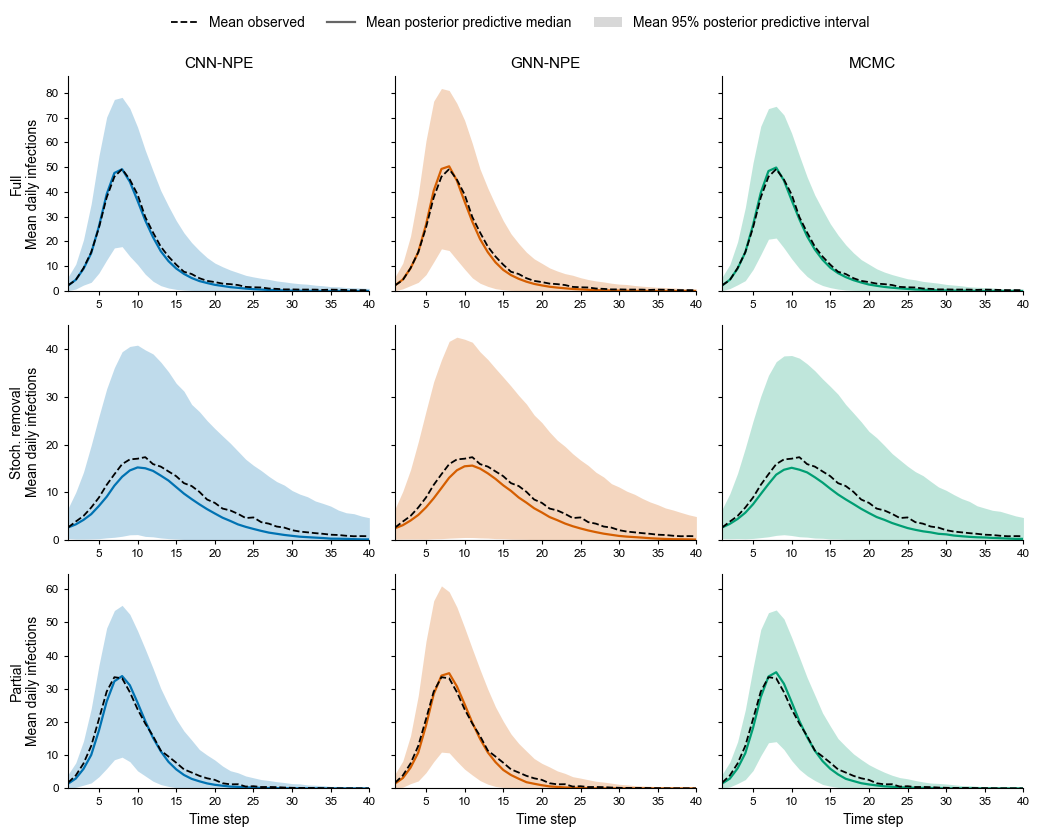

In [158]:
fig, axes = scenario_grid(height=2.5)
for r, sc in enumerate(SCENARIOS):
    z = np.load(EVAL_ROOT / sc / "eval" / "ppc_curves_mcmc_subset.npz")
    obs = z["observed_curves"]
    days = np.arange(1, obs.shape[1] + 1)
    curves = {"CNN-NPE": z["cnn_curves"], "GNN-NPE": z["gnn_curves"], "MCMC": z["mcmc_curves"]}
    ymax = max(obs.mean(axis=0).max(), *[np.percentile(v, 97.5, axis=1).mean(axis=0).max() for v in curves.values()]) * 1.06
    for c, m in enumerate(METHOD_ORDER):
        ax = axes[r, c]
        v = curves[m]
        ax.fill_between(days, np.percentile(v, 2.5, axis=1).mean(axis=0), np.percentile(v, 97.5, axis=1).mean(axis=0),
                        color=METHOD_COLORS[m], alpha=0.25, linewidth=0)
        ax.plot(days, np.median(v, axis=1).mean(axis=0), color=METHOD_COLORS[m], linewidth=1.6)
        ax.plot(days, obs.mean(axis=0), color="black", linewidth=1.3, linestyle="--")
        ax.set_xlim(1, obs.shape[1])
        ax.set_ylim(0, ymax)
        style(ax)
        if r == 0:
            ax.set_title(m, fontsize=11)
        if c == 0:
            ax.set_ylabel(f"{SCENARIO_LABELS[sc]}\nMean daily infections", fontsize=10)
        else:
            ax.set_yticklabels([])
        if r == len(SCENARIOS) - 1:
            ax.set_xlabel("Time step", fontsize=10)
handles = [Line2D([0], [0], color="black", linestyle="--", linewidth=1.3, label="Mean observed"),
           Line2D([0], [0], color="#666666", linewidth=1.6, label="Mean posterior predictive median"),
           Patch(facecolor="#666666", alpha=0.25, label="Mean 95% posterior predictive interval")]
fig.tight_layout()
top_legend(fig, handles)
save(fig, "FigS_ppc_avg_npe_mcmc")

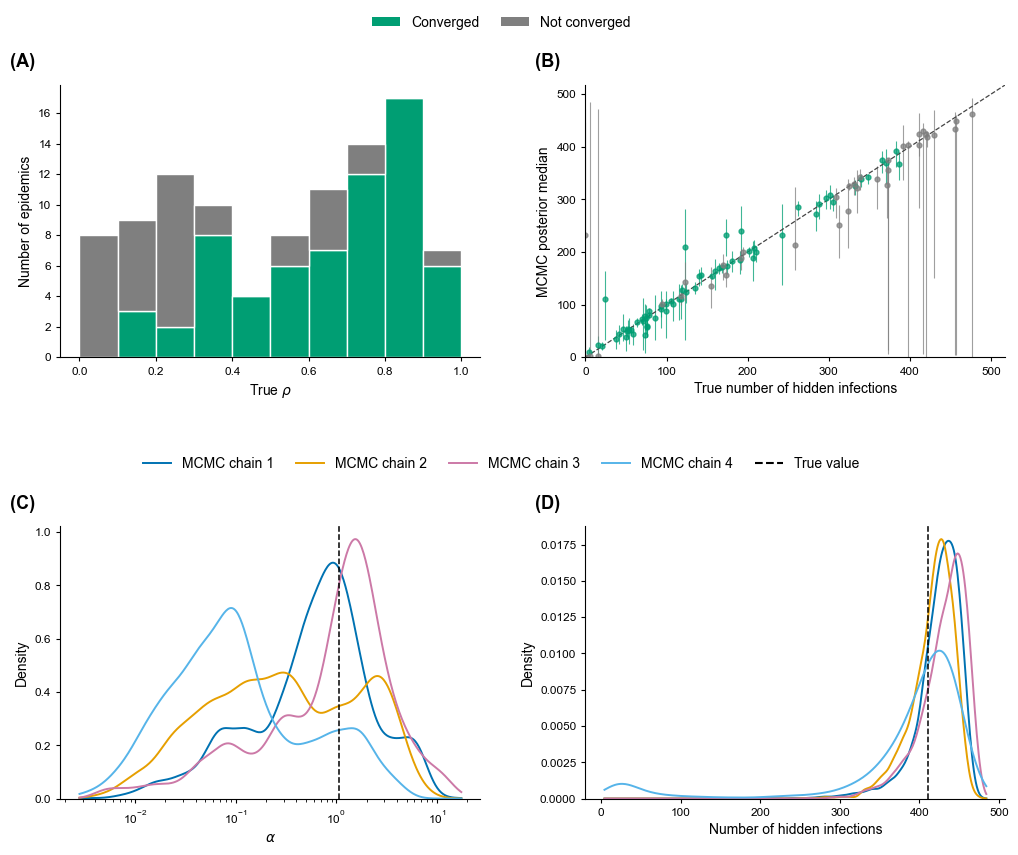

In [159]:
SUP = OUT / "mcmc_supplement"
CONV_COLORS = {True: "#009E73", False: "#7F7F7F"}
CHAIN_COLORS = ["#0072B2", "#E69F00", "#CC79A7", "#56B4E9"]

rho = pd.read_csv(SUP / "partial_rho_convergence.csv")
hid = pd.read_csv(SUP / "partial_hidden_infections.csv")
z = np.load(SUP / "partial_nonconverged_example.npz", allow_pickle=True)
chains, lat, theta = z["mcmc_chains"].astype(float), z["mcmc_latent_chains"].astype(float), z["theta"].astype(float)

fig = plt.figure(figsize=(10.5, 8.6))
gs = fig.add_gridspec(2, 2, left=0.08, right=0.98, top=0.90, bottom=0.07, hspace=0.62, wspace=0.25)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(2)] for r in range(2)])

ax = axes[0, 0]
ax.hist([rho.loc[rho["converged"], "rho_true"], rho.loc[~rho["converged"], "rho_true"]], bins=np.linspace(0, 1, 11),
        stacked=True, color=[CONV_COLORS[True], CONV_COLORS[False]], edgecolor="white")
ax.set_xlabel(r"True $\rho$", fontsize=10)
ax.set_ylabel("Number of epidemics", fontsize=10)

ax = axes[0, 1]
for c in (True, False):
    g = hid[hid["converged"] == c]
    ax.errorbar(g["true_hidden"], g["post_median"], yerr=np.vstack([g["post_median"] - g["post_q025"], g["post_q975"] - g["post_median"]]),
                fmt="o", markersize=3.5, color=CONV_COLORS[c], ecolor=CONV_COLORS[c], elinewidth=0.8, alpha=0.75)
hi = float(max(hid["true_hidden"].max(), hid["post_q975"].max())) * 1.05
ax.plot([0, hi], [0, hi], color="#444444", linestyle="--", linewidth=0.9)
ax.set_xlim(0, hi)
ax.set_ylim(0, hi)
ax.set_xlabel("True number of hidden infections", fontsize=10)
ax.set_ylabel("MCMC posterior median", fontsize=10)

ax = axes[1, 0]
la = np.log10(chains[:, :, 0])
lo, hi = np.quantile(la, [0.002, 0.998])
lo, hi = min(lo, np.log10(theta[0])), max(hi, np.log10(theta[0]))
grid = np.linspace(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo), 400)
for i in range(la.shape[0]):
    ax.plot(10 ** grid, gaussian_kde(la[i])(grid), color=CHAIN_COLORS[i % 4], linewidth=1.4)
ax.axvline(theta[0], color="black", linestyle="--", linewidth=1.1)
ax.set_xscale("log")
ax.set_ylim(bottom=0)
ax.set_xlabel(r"$\alpha$", fontsize=10)
ax.set_ylabel("Density", fontsize=10)

ax = axes[1, 1]
grid = np.linspace(lat.min(), lat.max(), 400)
for i in range(lat.shape[0]):
    ax.plot(grid, gaussian_kde(lat[i])(grid), color=CHAIN_COLORS[i % 4], linewidth=1.4)
th = hid.loc[hid["obs_idx"] == int(z["obs_idx"]), "true_hidden"]
if len(th):
    ax.axvline(float(th.iloc[0]), color="black", linestyle="--", linewidth=1.1)
ax.set_ylim(bottom=0)
ax.set_xlabel("Number of hidden infections", fontsize=10)
ax.set_ylabel("Density", fontsize=10)

for a, letter in zip(axes.ravel(), "ABCD"):
    style(a)
    panel_label(a, letter)
conv = [Patch(facecolor=CONV_COLORS[True], label="Converged"), Patch(facecolor=CONV_COLORS[False], label="Not converged")]
chain_h = [Line2D([0], [0], color=CHAIN_COLORS[i], linewidth=1.4, label=f"MCMC chain {i + 1}") for i in range(4)]
truth = Line2D([0], [0], color="black", linestyle="--", label="True value")
top_legend(fig, conv, y=axes[0, 0].get_position().y1 + 0.05)
top_legend(fig, chain_h + [truth], y=axes[1, 0].get_position().y1 + 0.05)
save(fig, "FigS_partial_mcmc")


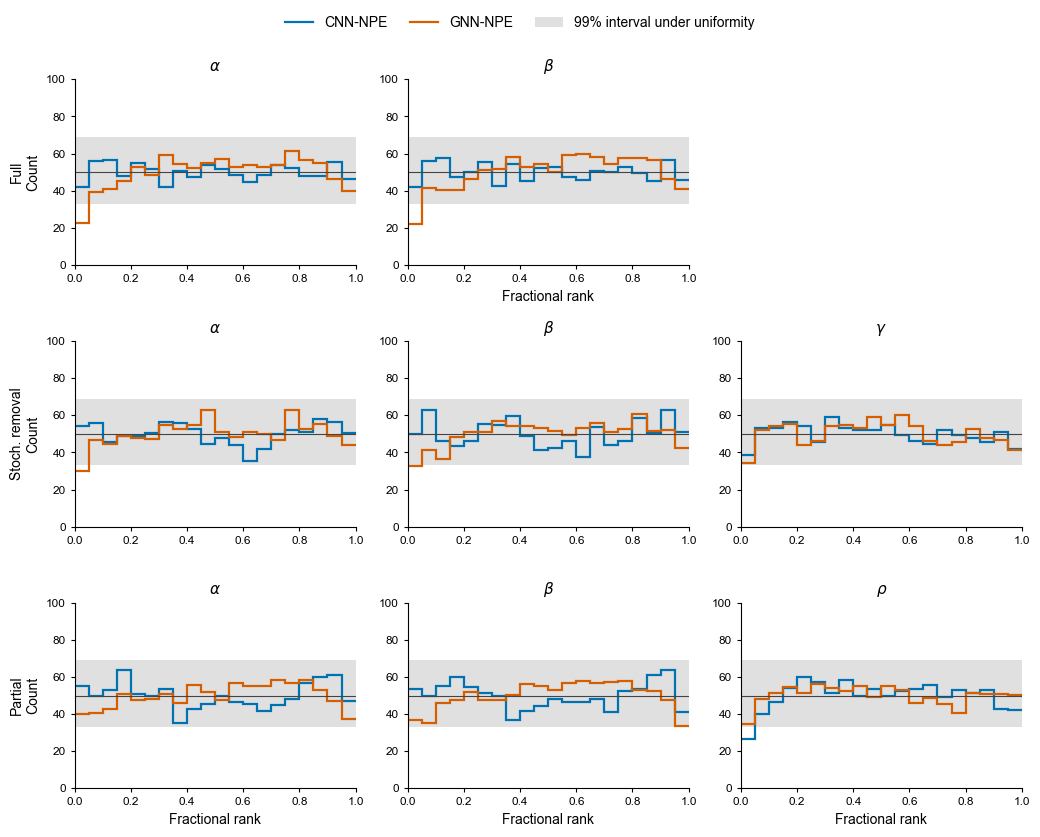

In [160]:
fig, axes = scenario_grid(height=2.5)
for r, sc in enumerate(SCENARIOS):
    d = np.load(OUT / "sbc" / f"sbc_{sc}.npz", allow_pickle=True)
    names = [str(p) for p in d["param_names"]]
    edges = d["edges"]
    expected = int(d["n_epidemics"]) / (len(edges) - 1)
    for c in range(3):
        ax = axes[r, c]
        if c >= len(names):
            ax.set_visible(False)
            continue
        ax.axhspan(float(d["band_lower"]), float(d["band_upper"]), color=BAND_COLOR, alpha=0.45, linewidth=0)
        ax.axhline(expected, color="#444444", linewidth=0.8)
        for m in ("CNN-NPE", "GNN-NPE"):
            ax.stairs(d[f"{METHOD_KEYS[m]}_counts_mean"][c], edges, baseline=None, color=METHOD_COLORS[m], linewidth=1.6)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 2 * expected)
        ax.set_title(PARAM_TEX[names[c]], fontsize=11)
        style(ax)
        if c == 0:
            ax.set_ylabel(f"{SCENARIO_LABELS[sc]}\nCount", fontsize=10)
        if r == len(SCENARIOS) - 1 or (r == 0 and c == len(names) - 1):
            ax.set_xlabel("Fractional rank", fontsize=10)
handles = [Line2D([0], [0], color=METHOD_COLORS[m], linewidth=1.6, label=m) for m in ("CNN-NPE", "GNN-NPE")]
handles.append(Patch(facecolor=BAND_COLOR, alpha=0.45, label="99% interval under uniformity"))
fig.tight_layout()
top_legend(fig, handles)
save(fig, "Fig_sbc")

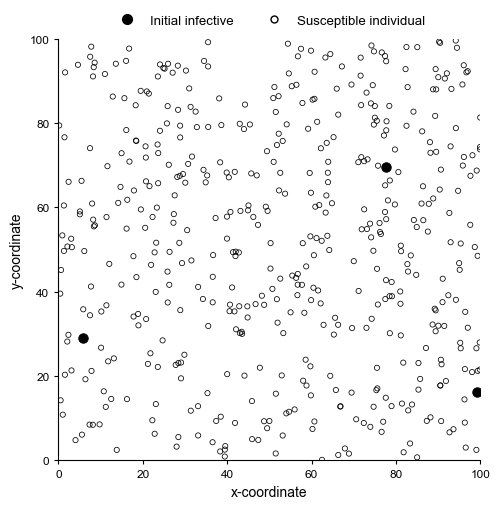

In [161]:
cfg = np.load(OUT / "configs" / "ilm_config.npz")
pos, seed_idx, side = cfg["positions"], cfg["seed_idx"], float(cfg["region_side"])
is_seed = np.zeros(len(pos), dtype=bool)
is_seed[seed_idx] = True

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(pos[~is_seed, 0], pos[~is_seed, 1], s=14, facecolors="none", edgecolors="black", linewidths=0.55)
ax.scatter(pos[is_seed, 0], pos[is_seed, 1], s=46, facecolors="black", edgecolors="black", linewidths=0.7)
ax.set_xlim(0, side)
ax.set_ylim(0, side)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x-coordinate", fontsize=10)
ax.set_ylabel("y-coordinate", fontsize=10)
style(ax)
ax.legend(handles=[Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="black", markeredgecolor="black",
                        markersize=7, label="Initial infective"),
                 Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="none", markeredgecolor="black",
                        markersize=5, label="Susceptible individual")], loc="lower center", bbox_to_anchor=(0.5, 1.0),
          ncol=2, frameon=False, fontsize=9.5)
fig.tight_layout()
save(fig, "FigS_spatial_population")

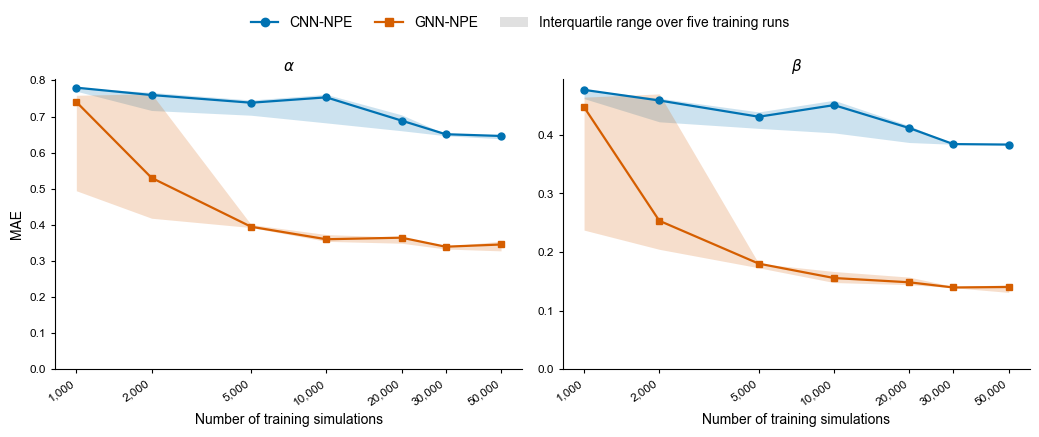

In [162]:
lc = pd.read_csv(OUT / "learning_curve" / "learning_curve_full_all.csv")
lc = lc[lc["scenario"] == "full"]
LC_MODELS = {"cnn": "CNN-NPE", "gnn": "GNN-NPE"}

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), squeeze=False)
for c, p in enumerate(["alpha", "beta"]):
    ax = axes[0, c]
    for tag, m in LC_MODELS.items():
        g = lc[lc["model"] == tag].groupby("N")[f"mae_{p}"]
        q = g.quantile([0.25, 0.5, 0.75]).unstack()
        ax.fill_between(q.index, q[0.25], q[0.75], color=METHOD_COLORS[m], alpha=0.2, linewidth=0)
        ax.plot(q.index, q[0.5], color=METHOD_COLORS[m], marker=METHOD_MARKERS[m], markersize=5, linewidth=1.6)
    ax.set_xscale("log")
    ns = sorted(lc["N"].unique())
    ax.set_xticks(ns)
    ax.set_xticklabels([f"{n:,}" for n in ns], rotation=35, ha="right")
    ax.minorticks_off()
    ax.set_ylim(bottom=0)
    ax.set_title(PARAM_TEX[p], fontsize=11)
    ax.set_xlabel("Number of training simulations", fontsize=10)
    if c == 0:
        ax.set_ylabel("MAE", fontsize=10)
    style(ax)
handles = [Line2D([0], [0], color=METHOD_COLORS[m], marker=METHOD_MARKERS[m], linewidth=1.6, label=m) for m in LC_MODELS.values()]
handles.append(Patch(facecolor="#666666", alpha=0.2, label="Interquartile range over five training runs"))
fig.tight_layout()
top_legend(fig, handles)
save(fig, "FigS_learning_curve")

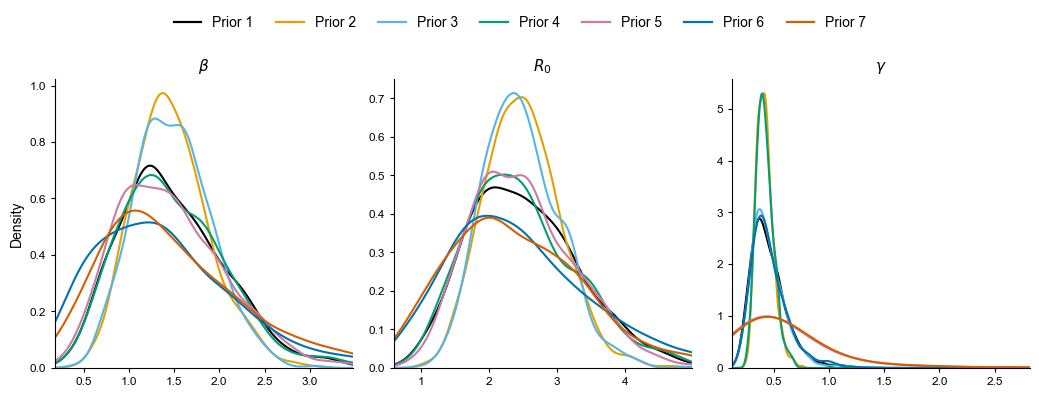

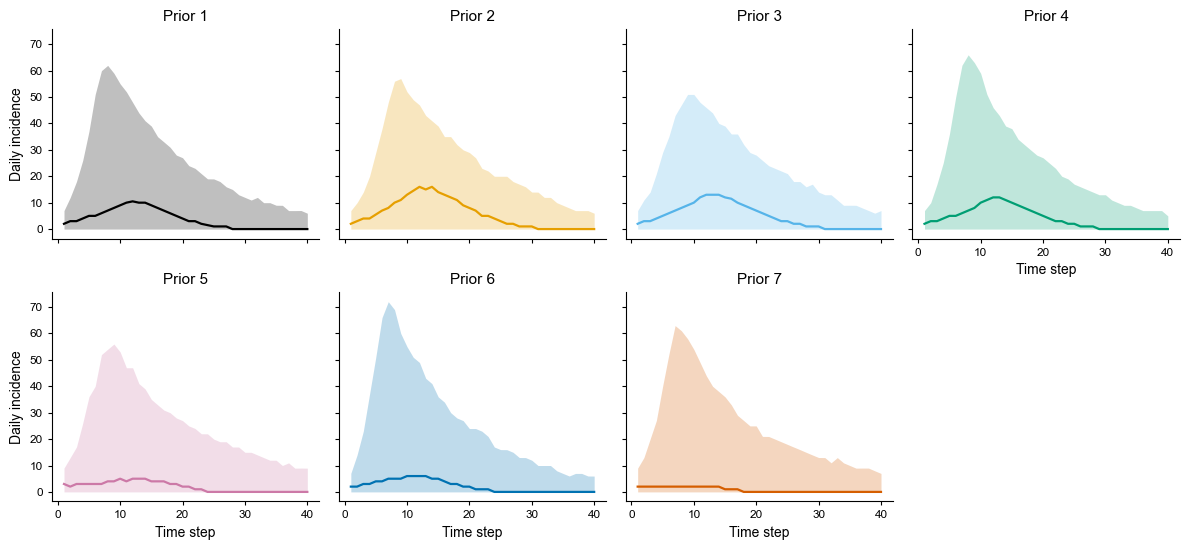

In [163]:
def prior_dir(v):
    return OUT / "strict" / "gamma" / "final" if v == "baseline" else OUT / "prior_sensitivity" / v


stats = {v: pd.read_csv(prior_dir(v) / "test_stats.csv") for v in PRIOR_VARIANTS}
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6), squeeze=False)
for c, (col, p) in enumerate([("beta", "beta"), ("r0", "R0"), ("gamma", "gamma")]):
    ax = axes[0, c]
    pooled = np.concatenate([s[col].to_numpy() for s in stats.values()])
    grid = np.linspace(*np.quantile(pooled, [0.002, 0.99]), 400)
    for v in PRIOR_VARIANTS:
        ax.plot(grid, gaussian_kde(stats[v][col].to_numpy())(grid), linewidth=1.5, color=PRIOR_COLORS[v])
    ax.set_xlim(grid[0], grid[-1])
    ax.set_ylim(bottom=0)
    ax.set_title(PARAM_TEX[p], fontsize=11)
    if c == 0:
        ax.set_ylabel("Density", fontsize=10)
    style(ax)
handles = [Line2D([0], [0], color=PRIOR_COLORS[v], linewidth=1.6, label=PRIOR_LABELS[v]) for v in PRIOR_VARIANTS]
fig.tight_layout()
top_legend(fig, handles)
save(fig, "FigS_prior_densities")

fig, axes = plt.subplots(2, 4, figsize=(12.0, 5.6), squeeze=False, sharex=True, sharey=True)
for k, v in enumerate(PRIOR_VARIANTS):
    ax = axes.ravel()[k]
    z = np.load(prior_dir(v) / "test.npz", allow_pickle=True)
    x, T = z["x"].astype(int), int(z["T"])
    daily = np.stack([(x == t).sum(axis=1) for t in range(1, T + 1)], axis=1)
    days = np.arange(1, T + 1)
    lo, med, hi = np.quantile(daily, [0.025, 0.5, 0.975], axis=0)
    ax.fill_between(days, lo, hi, color=PRIOR_COLORS[v], alpha=0.25, linewidth=0)
    ax.plot(days, med, color=PRIOR_COLORS[v], linewidth=1.6)
    ax.set_title(PRIOR_LABELS[v], fontsize=11)
    style(ax)
    if k % 4 == 0:
        ax.set_ylabel("Daily incidence", fontsize=10)
    if k >= 3:
        ax.set_xlabel("Time step", fontsize=10)
        ax.xaxis.set_tick_params(labelbottom=True)
axes.ravel()[-1].set_visible(False)
fig.tight_layout()
save(fig, "FigS_prior_predictive")


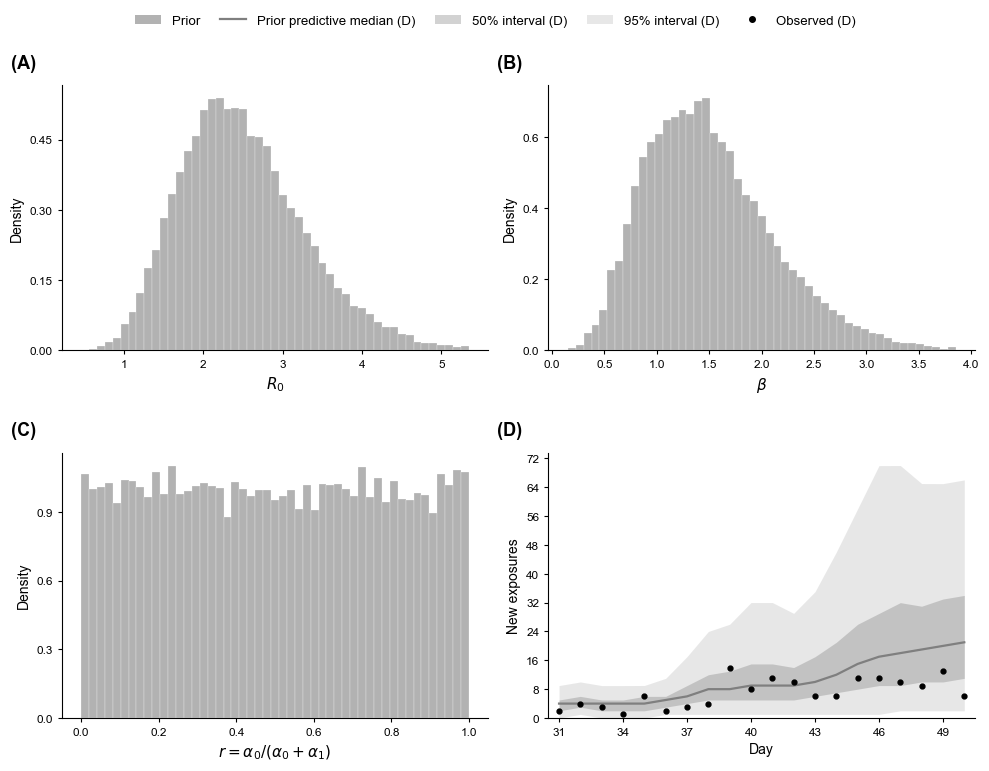

In [164]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

ROOT = Path("/Users/MYC/Desktop/博后项目/NPE_embed_ILM/9.25")
FMD_ROOT = ROOT / "output_fmd"
FIG_DIR = ROOT / "figures"

C_PRIOR = "#7F7F7F"
PANELS = [(3, r"$R_0$"), (2, r"$\beta$"), (4, r"$r=\alpha_0/(\alpha_0+\alpha_1)$")]


def style(ax):
    ax.tick_params(axis="both", labelsize=8.5, length=3)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)


def panel_label(ax, letter):
    ax.text(-0.12, 1.05, f"({letter})", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")


cfg = np.load(FMD_ROOT / "fmd_config.npz", allow_pickle=True)
prior = np.load(FMD_ROOT / "paper" / "derived_samples.npz", allow_pickle=True)["prior"].astype(float)
pp = np.load(FMD_ROOT / "paper" / "prior_predictive.npz")
t0 = int(cfg["t_start"])
T = int(cfg["T"])
days = t0 + np.arange(1, T + 1)

fig, axes = plt.subplots(2, 2, figsize=(10.0, 7.6))

for k, (j, label) in enumerate(PANELS):
    ax = axes.ravel()[k]
    v = prior[:, j]
    hi = np.quantile(v, 0.998) if j != 4 else 1.0
    ax.hist(v, bins=np.linspace(0 if j == 4 else v.min(), hi, 50), density=True, color=C_PRIOR, alpha=0.6,
            edgecolor="white", linewidth=0.3)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel("Density", fontsize=10)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    style(ax)
    panel_label(ax, "ABC"[k])

ax = axes[1, 1]
daily = pp["daily"].astype(float)
q = np.percentile(daily, [2.5, 25, 50, 75, 97.5], axis=0)
ax.fill_between(days, q[0], q[4], color=C_PRIOR, alpha=0.18, linewidth=0)
ax.fill_between(days, q[1], q[3], color=C_PRIOR, alpha=0.35, linewidth=0)
ax.plot(days, q[2], color=C_PRIOR, linewidth=1.6)
ax.plot(days, pp["observed"], color="black", linestyle="none", marker="o", markersize=3.5)
ax.set_xlim(t0 + 0.5, t0 + T + 0.5)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(t0 + 1, t0 + T + 1, 3))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Day", fontsize=10)
ax.set_ylabel("New exposures", fontsize=10)
style(ax)
panel_label(ax, "D")

handles = [Patch(facecolor=C_PRIOR, alpha=0.6, label="Prior"),
           Line2D([0], [0], color=C_PRIOR, linewidth=1.6, label="Prior predictive median (D)"),
           Patch(facecolor=C_PRIOR, alpha=0.35, label="50% interval (D)"),
           Patch(facecolor=C_PRIOR, alpha=0.18, label="95% interval (D)"),
           Line2D([0], [0], color="black", linestyle="none", marker="o", markersize=4, label="Observed (D)")]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.97), ncol=len(handles), frameon=False,
           fontsize=9.5, columnspacing=1.5)
fig.tight_layout(rect=[0, 0, 1, 0.97], h_pad=2.0)
fig.savefig(FIG_DIR / "FigS_fmd_prior.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "FigS_fmd_prior.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

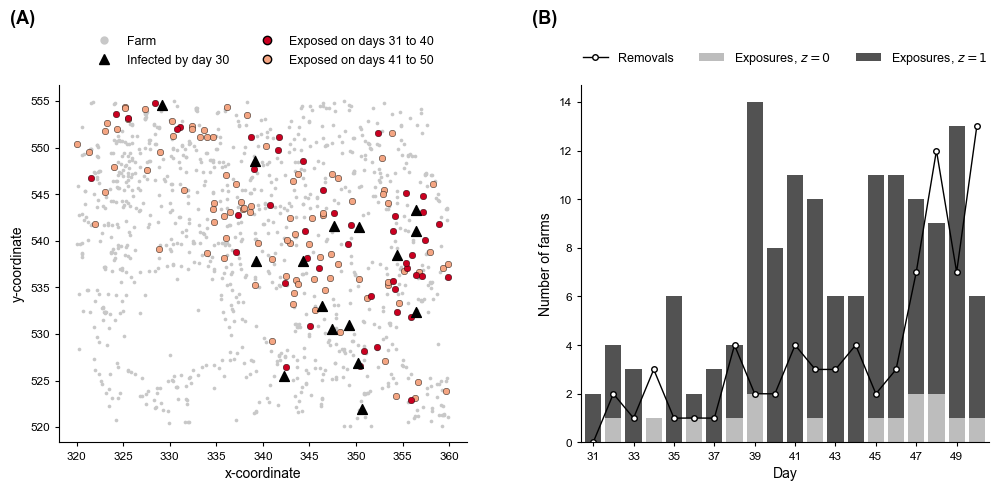

In [165]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

ROOT = Path("/Users/MYC/Desktop/博后项目/NPE_embed_ILM/9.25")
FMD_ROOT = ROOT / "output_fmd"
FIG_DIR = ROOT / "figures"

C_FARM = "#c8c8c8"
C_EARLY = "#CA0020"
C_LATE = "#F4A582"
C_Z0 = "#BDBDBD"
C_Z1 = "#525252"


def style(ax):
    ax.tick_params(axis="both", labelsize=8.5, length=3)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)


def panel_label(ax, letter):
    ax.text(-0.12, 1.16, f"({letter})", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")


data = np.loadtxt(ROOT / "fmd_clean.txt")
cfg = np.load(FMD_ROOT / "fmd_config.npz", allow_pickle=True)
obs = np.load(FMD_ROOT / "eval" / "ppc_observed.npz")
t0 = int(cfg["t_start"])
T = int(cfg["T"])
half = T // 2
pos = cfg["positions"].astype(float)
exp_obs = cfg["exp_obs"].astype(int)
before = np.concatenate([cfg["active_idx"], cfg["exposed_idx"], cfg["removed_idx"]])
early = (exp_obs >= 1) & (exp_obs <= half)
late = exp_obs > half

fig, axes = plt.subplots(1, 2, figsize=(12.0, 5.6), gridspec_kw={"wspace": 0.28})
box = (pos[:, 1].max() - pos[:, 1].min()) / (pos[:, 0].max() - pos[:, 0].min())

ax = axes[0]
ax.scatter(pos[:, 0], pos[:, 1], s=7, color=C_FARM, linewidths=0, zorder=1)
ax.scatter(pos[late, 0], pos[late, 1], s=22, color=C_LATE, edgecolors="black", linewidths=0.3, zorder=2)
ax.scatter(pos[early, 0], pos[early, 1], s=22, color=C_EARLY, edgecolors="black", linewidths=0.3, zorder=3)
ax.scatter(pos[before, 0], pos[before, 1], marker="^", s=50, color="black", zorder=4)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x-coordinate", fontsize=10)
ax.set_ylabel("y-coordinate", fontsize=10)
handles = [
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=C_FARM, markeredgecolor=C_FARM, markersize=5, label="Farm"),
    Line2D([0], [0], marker="^", linestyle="none", color="black", markersize=7, label=f"Infected by day {t0}"),
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=C_EARLY, markeredgecolor="black", markersize=6,
           label=f"Exposed on days {t0 + 1} to {t0 + half}"),
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=C_LATE, markeredgecolor="black", markersize=6,
           label=f"Exposed on days {t0 + half + 1} to {t0 + T}"),
]
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize=9)
style(ax)
ax.set_box_aspect(box)
panel_label(ax, "A")

ax = axes[1]
wd = t0 + np.arange(1, T + 1)
ax.bar(wd, obs["exposures_z0"], width=0.8, color=C_Z0, linewidth=0, label="Exposures, $z=0$")
ax.bar(wd, obs["exposures_z1"], width=0.8, bottom=obs["exposures_z0"], color=C_Z1, linewidth=0, label="Exposures, $z=1$")
rem_day = data[data[:, 5] > 0, 6].astype(int)
removals = np.array([(rem_day == d).sum() for d in wd])
ax.plot(wd, removals, color="black", marker="o", markersize=4, markerfacecolor="white",
        linewidth=1.0, label="Removals")
ax.set_xlim(t0 + 0.4, t0 + T + 0.6)
ax.set_xticks(np.arange(t0 + 1, t0 + T + 1, 2))
ax.set_ylim(bottom=0)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Day", fontsize=10)
ax.set_ylabel("Number of farms", fontsize=10)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False, fontsize=9)
ax.set_box_aspect(box)
style(ax)
panel_label(ax, "B")

fig.savefig(FIG_DIR / "Fig_fmd_data.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "Fig_fmd_data.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

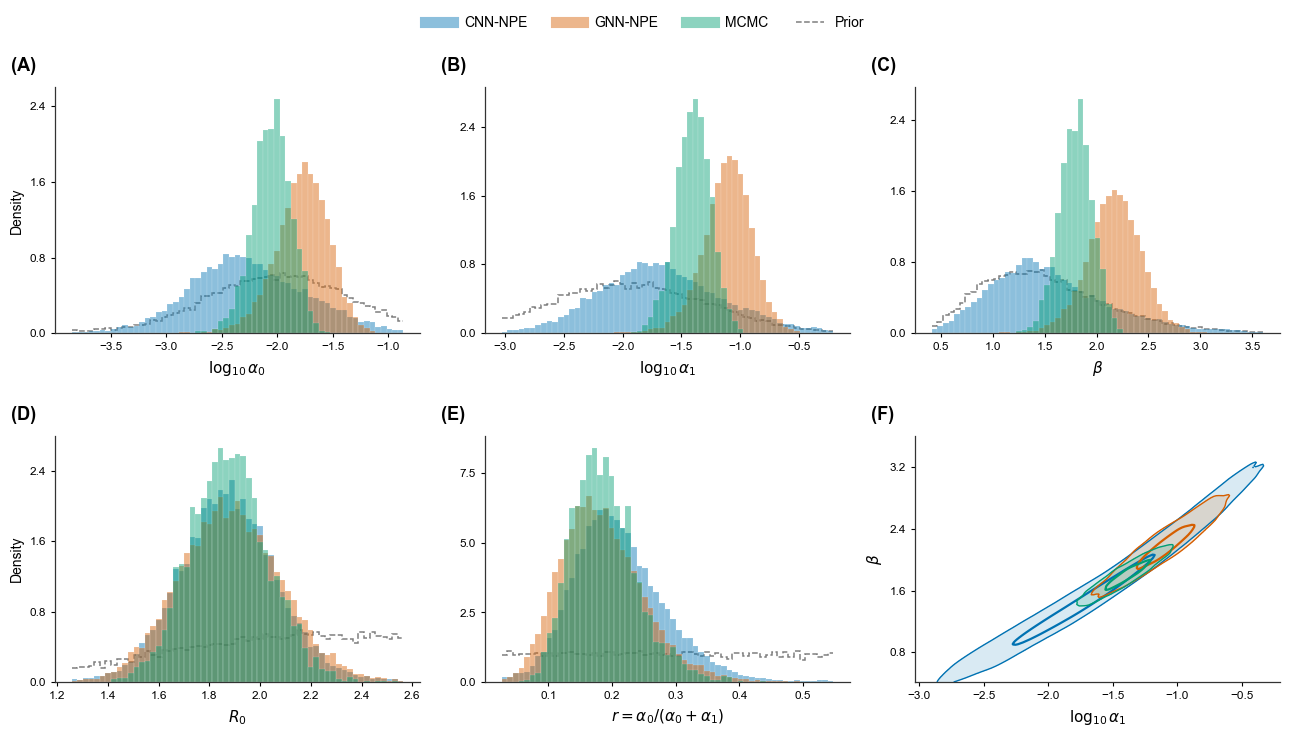

In [166]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

ROOT = Path("/Users/MYC/Desktop/博后项目/NPE_embed_ILM/9.25")
FMD_ROOT = ROOT / "output_fmd"
FIG_DIR = ROOT / "figures"

METHOD_ORDER = ["CNN-NPE", "GNN-NPE", "MCMC"]
METHOD_KEYS = {"CNN-NPE": "cnn", "GNN-NPE": "gnn", "MCMC": "mcmc"}
METHOD_COLORS = {"CNN-NPE": "#0072B2", "GNN-NPE": "#D55E00", "MCMC": "#009E73"}
PRIOR_COLOR = "#7F7F7F"
PANELS = [
    (0, True, r"$\log_{10}\alpha_0$"),
    (1, True, r"$\log_{10}\alpha_1$"),
    (2, False, r"$\beta$"),
    (3, False, r"$R_0$"),
    (4, False, r"$r=\alpha_0/(\alpha_0+\alpha_1)$"),
]

d = np.load(FMD_ROOT / "paper" / "derived_samples.npz", allow_pickle=True)
post = {m: d[METHOD_KEYS[m]].astype(float) for m in METHOD_ORDER}
prior = d["prior"].astype(float)


def tr(x, j, log):
    return np.log10(x[:, j]) if log else x[:, j]


def style(ax):
    ax.tick_params(axis="both", labelsize=8.5, length=3)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color("#333333")
        ax.spines[s].set_linewidth(0.9)


def panel_label(ax, letter):
    ax.text(-0.12, 1.05, f"({letter})", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")


def hpd_levels(kde, pts, probs):
    dens = kde(pts)
    return [np.quantile(dens, 1.0 - p) for p in probs]


fig, axes = plt.subplots(2, 3, figsize=(13.0, 7.0))
letters = "ABCDEF"

for k, (j, log, label) in enumerate(PANELS):
    ax = axes.ravel()[k]
    vals = {m: tr(post[m], j, log) for m in METHOD_ORDER}
    pooled = np.concatenate(list(vals.values()))
    lo, hi = np.quantile(pooled, [0.002, 0.998])
    bins = np.linspace(lo, hi, 60)
    pv = tr(prior, j, log)
    pd_, _ = np.histogram(pv, bins=bins)
    ax.stairs(pd_ / (len(pv) * np.diff(bins)), bins, color=PRIOR_COLOR, linestyle="--", linewidth=1.1, baseline=None)
    for m in METHOD_ORDER:
        ax.hist(vals[m], bins=bins, density=True, alpha=0.45, color=METHOD_COLORS[m], edgecolor="white", linewidth=0.2)
    ax.set_xlabel(label, fontsize=11, labelpad=5)
    if k % 3 == 0:
        ax.set_ylabel("Density", fontsize=10)
    panel_label(ax, letters[k])
    style(ax)

ax = axes.ravel()[5]
allx = np.concatenate([np.log10(post[m][:, 1]) for m in METHOD_ORDER])
ally = np.concatenate([post[m][:, 2] for m in METHOD_ORDER])
xl = np.quantile(allx, [0.002, 0.998])
yl = np.quantile(ally, [0.002, 0.998])
for m in METHOD_ORDER:
    x = np.log10(post[m][:, 1])
    y = post[m][:, 2]
    rng = np.random.default_rng(0)
    pick = rng.choice(len(x), size=min(4000, len(x)), replace=False)
    kde = gaussian_kde(np.vstack([x[pick], y[pick]]))
    gx = np.linspace(xl[0], xl[1], 150)
    gy = np.linspace(yl[0], yl[1], 150)
    X, Y = np.meshgrid(gx, gy)
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    lv = hpd_levels(kde, np.vstack([x[pick], y[pick]]), [0.95, 0.5])
    ax.contourf(X, Y, Z, levels=[lv[0], Z.max()], colors=[METHOD_COLORS[m]], alpha=0.15)
    ax.contour(X, Y, Z, levels=lv, colors=[METHOD_COLORS[m]], linewidths=[1.0, 1.6])
ax.set_xlabel(r"$\log_{10}\alpha_1$", fontsize=11, labelpad=5)
ax.set_ylabel(r"$\beta$", fontsize=11)
ax.set_xlim(*xl)
ax.set_ylim(*yl)
panel_label(ax, "F")
style(ax)

handles = [Line2D([0], [0], color=METHOD_COLORS[m], linewidth=8, alpha=0.45, label=m) for m in METHOD_ORDER]
handles.append(Line2D([0], [0], color=PRIOR_COLOR, linestyle="--", linewidth=1.1, label="Prior"))
fig.tight_layout(h_pad=2.0)
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(handles), frameon=False, fontsize=10)
fig.savefig(FIG_DIR / "Fig_fmd_posterior.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "Fig_fmd_posterior.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

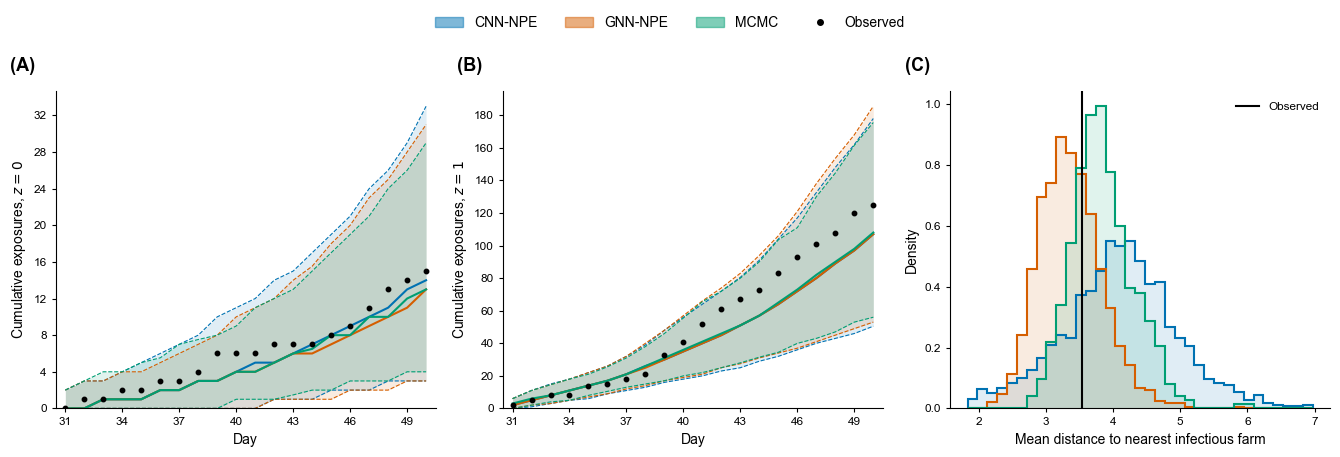

In [167]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

ROOT = Path("/Users/MYC/Desktop/博后项目/NPE_embed_ILM/9.25")
FMD_ROOT = ROOT / "output_fmd"
EVAL_DIR = FMD_ROOT / "eval"
FIG_DIR = ROOT / "figures"

SEEDS = [1, 2, 3, 4, 5]
METHOD_ORDER = ["CNN-NPE", "GNN-NPE", "MCMC"]
METHOD_KEYS = {"CNN-NPE": "cnn", "GNN-NPE": "gnn", "MCMC": "mcmc", "Prior": "prior"}
METHOD_FILES = {"CNN-NPE": [f"cnn_seed{s}" for s in SEEDS], "GNN-NPE": [f"gnn_seed{s}" for s in SEEDS],
                "MCMC": ["mcmc_seed0"]}
METHOD_COLORS = {"CNN-NPE": "#0072B2", "GNN-NPE": "#D55E00", "MCMC": "#009E73", "Prior": "#7F7F7F"}


def load(method, key):
    return np.concatenate([np.load(EVAL_DIR / f"ppc_{f}.npz")[key] for f in METHOD_FILES[method]]).astype(float)


def style(ax):
    ax.tick_params(axis="both", labelsize=8.5, length=3)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)


def panel_label(ax, letter):
    ax.text(-0.12, 1.05, f"({letter})", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")


obs = np.load(EVAL_DIR / "ppc_observed.npz")
sp = np.load(FMD_ROOT / "paper" / "ppc_spatial.npz")
cfg = np.load(FMD_ROOT / "fmd_config.npz", allow_pickle=True)
t0 = int(cfg["t_start"])
T = int(obs["T"])
days = t0 + np.arange(1, T + 1)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

for k, (key, ylab) in enumerate([("exposures_z0", "Cumulative exposures, $z=0$"),
                                 ("exposures_z1", "Cumulative exposures, $z=1$")]):
    ax = axes[k]
    for m in METHOD_ORDER:
        lo, med, hi = np.percentile(np.cumsum(load(m, key), axis=1), [2.5, 50, 97.5], axis=0)
        ax.fill_between(days, lo, hi, color=METHOD_COLORS[m], alpha=0.12, linewidth=0)
        ax.plot(days, lo, color=METHOD_COLORS[m], linewidth=0.8, linestyle="--")
        ax.plot(days, hi, color=METHOD_COLORS[m], linewidth=0.8, linestyle="--")
        ax.plot(days, med, color=METHOD_COLORS[m], linewidth=1.5)
    ax.plot(days, np.cumsum(obs[key]), color="black", linestyle="none", marker="o", markersize=3.2)
    ax.set_xlim(t0 + 0.5, t0 + T + 0.5)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.arange(t0 + 1, t0 + T + 1, 3))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("Day", fontsize=10)
    ax.set_ylabel(ylab, fontsize=10)
    style(ax)
    panel_label(ax, "AB"[k])

ax = axes[2]
vals = {m: sp[METHOD_KEYS[m]] for m in METHOD_ORDER}
lo, hi = np.quantile(np.concatenate([vals[m] for m in METHOD_ORDER]), [0.002, 0.998])
bins = np.linspace(lo, hi, 36)
for m in METHOD_ORDER:
    ax.hist(vals[m], bins=bins, density=True, histtype="step", color=METHOD_COLORS[m], linewidth=1.5)
    ax.hist(vals[m], bins=bins, density=True, color=METHOD_COLORS[m], alpha=0.12)
ax.axvline(float(sp["observed"]), color="black", linewidth=1.5)
ax.set_xlabel("Mean distance to nearest infectious farm", fontsize=10)
ax.set_ylabel("Density", fontsize=10)
style(ax)
panel_label(ax, "C")

method_h = [Patch(facecolor=METHOD_COLORS[m], edgecolor=METHOD_COLORS[m], alpha=0.5, label=m) for m in METHOD_ORDER]
axes[2].legend(handles=[Line2D([0], [0], color="black", linewidth=1.5, label="Observed")], loc="upper right",
               frameon=False, fontsize=8.5)
fig.tight_layout()
fig.legend(handles=method_h + [Line2D([0], [0], color="black", linestyle="none", marker="o", markersize=4, label="Observed")],
           loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False, fontsize=10)
fig.savefig(FIG_DIR / "Fig_fmd_ppc.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "Fig_fmd_ppc.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

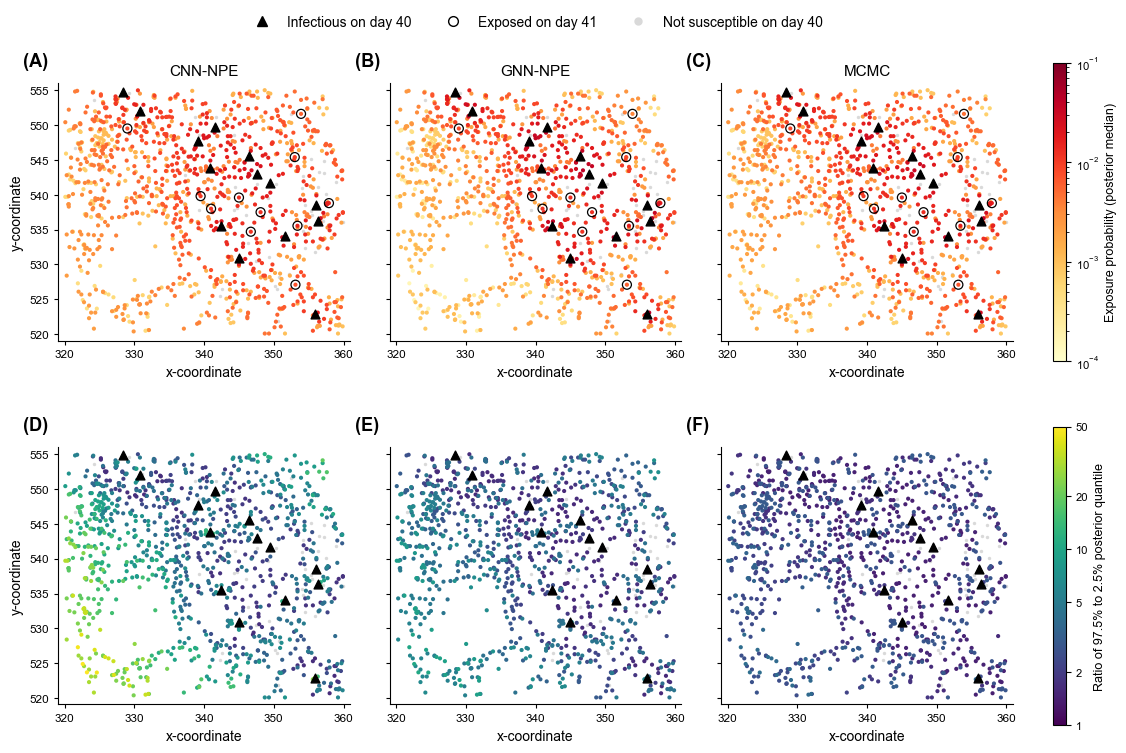

In [168]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

ROOT = Path("/Users/MYC/Desktop/博后项目/NPE_embed_ILM/9.25")
FMD_ROOT = ROOT / "output_fmd"
FIG_DIR = ROOT / "figures"

METHOD_ORDER = ["CNN-NPE", "GNN-NPE", "MCMC"]
METHOD_KEYS = {"CNN-NPE": "cnn", "GNN-NPE": "gnn", "MCMC": "mcmc"}
C_OTHER = "#d9d9d9"
RISK_RANGE = (1e-4, 0.1)
RATIO_RANGE = (1.0, 50.0)


def style(ax):
    ax.tick_params(axis="both", labelsize=8.5, length=3)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)


def panel_label(ax, letter):
    ax.text(-0.12, 1.05, f"({letter})", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")


cfg = np.load(FMD_ROOT / "fmd_config.npz", allow_pickle=True)
rk = np.load(FMD_ROOT / "paper" / "risk_map.npz")
pos = cfg["positions"].astype(float)
sus = rk["susceptible"]
inf = rk["infectious"]
nxt = rk["exposed_next"]
day = int(rk["day"])
other = np.setdiff1d(np.arange(len(pos)), sus)
pad = 1.0
xlim = (pos[:, 0].min() - pad, pos[:, 0].max() + pad)
ylim = (pos[:, 1].min() - pad, pos[:, 1].max() + pad)

fig = plt.figure(figsize=(13.0, 8.6))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.045], wspace=0.18, hspace=0.22)
rows = [
    ("median", LogNorm(*RISK_RANGE), "YlOrRd", "Exposure probability (posterior median)"),
    ("ratio", LogNorm(*RATIO_RANGE), "viridis", "Ratio of 97.5% to 2.5% posterior quantile"),
]
for r_, (kind, norm, cmap, cb_label) in enumerate(rows):
    for c, m in enumerate(METHOD_ORDER):
        ax = fig.add_subplot(gs[r_, c])
        k = METHOD_KEYS[m]
        val = rk[f"{k}_median"] if kind == "median" else rk[f"{k}_q975"] / rk[f"{k}_q025"]
        order = np.argsort(val)
        ax.scatter(pos[other, 0], pos[other, 1], s=6, color=C_OTHER, linewidths=0, zorder=1)
        sc = ax.scatter(pos[sus[order], 0], pos[sus[order], 1], c=val[order], cmap=cmap, norm=norm, s=9,
                        linewidths=0, zorder=2)
        if kind == "median":
            ax.scatter(pos[nxt, 0], pos[nxt, 1], s=42, facecolors="none", edgecolors="black", linewidths=0.9, zorder=3)
        ax.scatter(pos[inf, 0], pos[inf, 1], marker="^", s=40, color="black", zorder=4)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x-coordinate", fontsize=10)
        if c == 0:
            ax.set_ylabel("y-coordinate", fontsize=10)
        else:
            ax.set_yticklabels([])
        if r_ == 0:
            ax.set_title(m, fontsize=11)
        style(ax)
        panel_label(ax, "ABCDEF"[3 * r_ + c])
    cax = fig.add_subplot(gs[r_, 3])
    cb = fig.colorbar(sc, cax=cax)
    cb.set_label(cb_label, fontsize=9)
    cb.ax.tick_params(labelsize=8)
    if kind == "ratio":
        cb.set_ticks([1, 2, 5, 10, 20, 50])
        cb.set_ticklabels(["1", "2", "5", "10", "20", "50"])
        cb.ax.minorticks_off()

handles = [
    Line2D([0], [0], marker="^", linestyle="none", color="black", markersize=7, label=f"Infectious on day {day}"),
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="none", markeredgecolor="black", markersize=7,
           label=f"Exposed on day {day + 1}"),
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=C_OTHER, markeredgecolor=C_OTHER, markersize=5,
           label=f"Not susceptible on day {day}"),
]
x0, x1 = fig.axes[0].get_position().x0, fig.axes[2].get_position().x1
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=((x0 + x1) / 2, 0.905), ncol=3, frameon=False, fontsize=10)
fig.savefig(FIG_DIR / "Fig_fmd_risk.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "Fig_fmd_risk.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

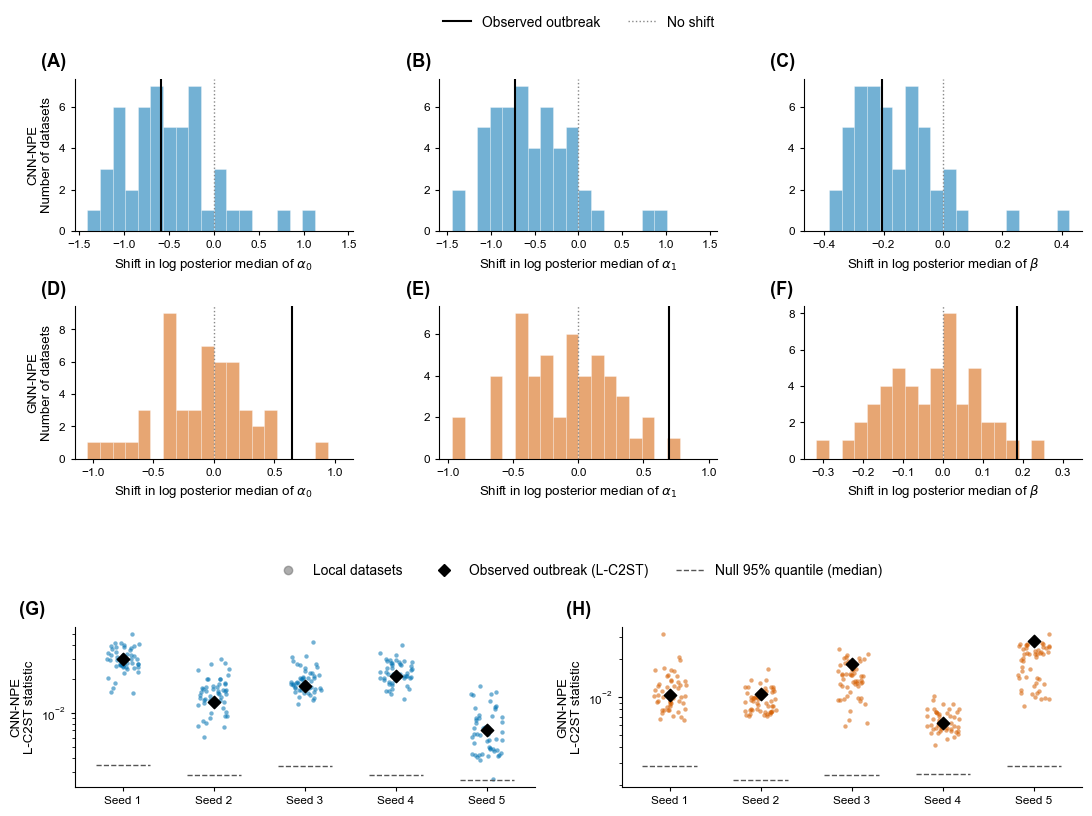

In [170]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
})

ROOT = Path("/Users/MYC/Desktop/博后项目/NPE_embed_ILM/9.25")
SI_ROOT = ROOT / "output_fmd" / "si_local"
FIG_DIR = ROOT / "figures"

SEEDS = [1, 2, 3, 4, 5]
MODELS = {"CNN-NPE": "cnn", "GNN-NPE": "gnn"}
COLORS = {"CNN-NPE": "#0072B2", "GNN-NPE": "#D55E00"}
PARAMS = [("alpha0", r"$\alpha_0$"), ("alpha1", r"$\alpha_1$"), ("beta", r"$\beta$")]

long = pd.read_csv(SI_ROOT / "local_check_long.csv")
summ = pd.read_csv(SI_ROOT / "local_check_summary.csv")
lc = pd.read_csv(SI_ROOT / "local_lc2st.csv")


def style(ax):
    ax.tick_params(axis="both", labelsize=8.5, length=3)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)


def panel_label(ax, letter):
    ax.text(-0.12, 1.05, f"({letter})", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")


fig = plt.figure(figsize=(13.0, 9.2))
gs = fig.add_gridspec(4, 6, height_ratios=[1, 1, 0.12, 1.05], hspace=0.62, wspace=0.9)
for r_, (name, key) in enumerate(MODELS.items()):
    for c, (p, label) in enumerate(PARAMS):
        ax = fig.add_subplot(gs[r_, 2 * c:2 * c + 2])
        per = long[(long.model == key) & (long.parameter == p)].groupby("dataset")["log_shift_vs_mcmc"].mean()
        real = float(summ[(summ.model == key) & (summ.parameter == p)]["real_log_shift_vs_mcmc"].iloc[0])
        lim = max(np.abs(per).max(), abs(real)) * 1.1
        ax.hist(per, bins=np.linspace(-lim, lim, 21), color=COLORS[name], alpha=0.55, edgecolor="white", linewidth=0.4)
        ax.axvline(0, color="#888888", linestyle=":", linewidth=1.0)
        ax.axvline(real, color="black", linewidth=1.5)
        ax.set_xlabel(f"Shift in log posterior median of {label}", fontsize=9.5)
        if c == 0:
            ax.set_ylabel(f"{name}\nNumber of datasets", fontsize=9.5)
        panel_label(ax, "ABCDEF"[3 * r_ + c])
        style(ax)

for c, (name, key) in enumerate(MODELS.items()):
    ax = fig.add_subplot(gs[3, 3 * c:3 * c + 3])
    rng = np.random.default_rng(1)
    for i, s in enumerate(SEEDS):
        g = lc[(lc.model == key) & (lc.seed == s)]
        loc = g[g.dataset != "real"]
        x = i + rng.uniform(-0.18, 0.18, len(loc))
        ax.scatter(x, loc["t_obs"], s=10, color=COLORS[name], alpha=0.55, linewidths=0)
        ax.hlines(np.median(loc["null_q95"]), i - 0.3, i + 0.3, color="#555555", linestyle="--", linewidth=1.0)
        ax.scatter([i], g[g.dataset == "real"]["t_obs"], marker="D", s=40, color="black", zorder=3)
    ax.set_yscale("log")
    ax.set_xticks(range(len(SEEDS)))
    ax.set_xticklabels([f"Seed {s}" for s in SEEDS], fontsize=8.5)
    ax.set_ylabel(f"{name}\nL-C2ST statistic", fontsize=9.5)
    panel_label(ax, "GH"[c])
    style(ax)

handles = [Line2D([0], [0], color="black", linewidth=1.5, label="Observed outbreak"),
           Line2D([0], [0], color="#888888", linestyle=":", linewidth=1.0, label="No shift"),
           Line2D([0], [0], marker="o", linestyle="none", color="#777777", alpha=0.6, label="Local datasets"),
           Line2D([0], [0], marker="D", linestyle="none", color="black", label="Observed outbreak (L-C2ST)"),
           Line2D([0], [0], color="#555555", linestyle="--", linewidth=1.0, label="Null 95% quantile (median)")]
x0, x1 = fig.axes[0].get_position().x0, fig.axes[2].get_position().x1
fig.legend(handles=handles[:2], loc="lower center", bbox_to_anchor=((x0 + x1) / 2, fig.axes[0].get_position().y1 + 0.04),
           ncol=2, frameon=False, fontsize=10)
fig.legend(handles=handles[2:], loc="lower center", bbox_to_anchor=((x0 + x1) / 2, fig.axes[6].get_position().y1 + 0.04),
           ncol=3, frameon=False, fontsize=10)
fig.savefig(FIG_DIR / "Fig_fmd_local.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "Fig_fmd_local.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)